# Team 7 · A clean CC0 swatch gallery

The app answers with **real photos** (MINC-2500 patches) and, first, with **clean swatches**: flat, background-free material samples that an architect could specify.

**Source.** [MatSynth](https://huggingface.co/datasets/gvecchio/MatSynth) lists 5,789 materials with a category and a licence. The full dataset is 433 GB (eight 4K maps per material), so we only read its **metadata** and take the materials that are:
- **CC0** (public domain: free to use and share, no credit required; we credit anyway);
- from **ambientCG** or **Poly Haven**, the two sources with a simple preview API;
- in a **building category**: ceramic, concrete, marble, metal, plaster, plastic, stone, terracotta, wood.

**Images.** Both sites publish a 512 px render of each material on a sphere. We keep:
- the **sphere** (shown in the app's zoom view);
- a **flat swatch**: the middle half of the sphere, where the surface faces the camera.

**Codes.** Every sphere goes through **the same ONNX model and preprocessing as a user's photo** (centre square → middle half → 224 px), so swatch codes and photo codes can be compared directly.

**Needs:** `data/matsynth/metadata.json` (MatSynth metadata, read once with pyarrow) and `01_autoencoder/models/material_finder.onnx`. Downloads about 1,300 small images (about 400 MB) into `data/swatches/` (git-ignored).

In [1]:
import io
import json
import re
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
import pandas as pd
from PIL import Image

AE_DIR = Path("..")
DATA_DIR = AE_DIR / ".." / "data"
RAW_DIR = DATA_DIR / "swatches" / "raw"
MODEL_DIR = AE_DIR / "models"
FIG_DIR = AE_DIR / "figures"
for folder in [RAW_DIR, MODEL_DIR / "swatch_thumbs", MODEL_DIR / "swatch_spheres"]:
    folder.mkdir(parents=True, exist_ok=True)

CATEGORIES = ["ceramic", "concrete", "fabric", "ground", "leather", "marble", "metal", "misc", "plaster",
              "plastic", "stone", "terracotta", "wood"]                 # MatSynth's label ids 0-12
BUILDING_CATS = {"ceramic", "concrete", "marble", "metal", "plaster", "plastic", "stone", "terracotta", "wood"}
BACKGROUND = (18, 18, 18)                                               # the app's dark background
pd.set_option("display.max_colwidth", 60)

meta_all = json.loads((DATA_DIR / "matsynth" / "metadata.json").read_text())
print(f"MatSynth: {len(meta_all):,} materials")
print("licences:", Counter(m["license"] for m in meta_all).most_common())

MatSynth: 5,789 materials
licences: [('CC0', 3454), ('CC BY-NC-ND 2.0', 2129), ('CC-BY', 206)]


# 1. Choose the materials

MatSynth's `terracotta` holds both bricks and roof tiles, and `ceramic` holds tiles and other ceramics. We give each swatch a more useful **material** name from its name and tags (brick, tile, paving…), and keep MatSynth's category next to it.

In [2]:
def asset_id(m):
    if m["source"] == "ambientcg":
        return re.search(r"id=([A-Za-z0-9_]+)", m["link"]).group(1)
    return m["link"].rstrip("/").split("/a/")[-1]


def material_name(m):
    cat = CATEGORIES[m["category"]]
    words = " ".join([m["name"], asset_id(m)] + (m["tags"] or [])).lower()
    if "brick" in words:
        return "brick"
    if "paving" in words or "cobble" in words:
        return "paving"
    if "roof" in words:
        return "roof tiles"
    if "tile" in words and cat in {"ceramic", "terracotta", "marble", "stone"}:
        return "tile"
    if cat == "stone" and ("rock" in words or "cliff" in words):
        return "rock"
    return cat


rows = []
for m in meta_all:
    cat = CATEGORIES[m["category"]]
    if (m["license"] or "").upper() != "CC0" or m["source"] not in {"ambientcg", "textures_heaven"} or cat not in BUILDING_CATS:
        continue
    rows.append({"key": f"{'acg' if m['source'] == 'ambientcg' else 'ph'}_{asset_id(m)}",
                 "asset": asset_id(m), "source": "ambientCG" if m["source"] == "ambientcg" else "Poly Haven",
                 "name": m["name"], "category": cat, "material": material_name(m), "link": m["link"],
                 "tags": m["tags"] or [], "authors": m["authors"] or []})
swatches = pd.DataFrame(rows).drop_duplicates("key").reset_index(drop=True)
print(f"{len(swatches):,} CC0 building materials")
pd.crosstab(swatches["material"], swatches["source"], margins=True)

1,280 CC0 building materials


source,Poly Haven,ambientCG,All
material,,,
brick,58,97,155
ceramic,0,3,3
concrete,46,95,141
marble,0,59,59
metal,9,168,177
paving,28,128,156
plaster,14,24,38
plastic,1,29,30
rock,37,0,37


# 2. Download the 512 px sphere previews

Polite: 4 downloads at a time, each file only once (kept in `data/swatches/raw/`).

In [3]:
def preview_url(row):
    if row["source"] == "ambientCG":
        return f"https://acg-media.struffelproductions.com/file/ambientCG-Web/media/thumbnail/512-PNG/{row['asset']}.png"
    return f"https://cdn.polyhaven.com/asset_img/thumbs/{row['asset']}.png?width=512&height=512"


def download(row):
    path = RAW_DIR / f"{row['key']}.img"
    if path.exists() and path.stat().st_size > 1000:
        return True
    try:
        req = Request(preview_url(row), headers={"User-Agent": "iaac-team7-material-finder (course project)"})
        data = urlopen(req, timeout=30).read()
        Image.open(io.BytesIO(data)).verify()
        path.write_bytes(data)
        return True
    except Exception as error:
        print("failed:", row["key"], error)
        return False


start = time.time()
with ThreadPoolExecutor(4) as pool:
    ok = list(pool.map(download, swatches.to_dict("records")))
swatches = swatches[ok].reset_index(drop=True)
print(f"{sum(ok):,} of {len(ok):,} downloaded in {time.time() - start:.0f} s")

1,280 of 1,280 downloaded in 141 s


# 3. Sphere, flat swatch and code for every material

In [4]:
session = ort.InferenceSession(str(MODEL_DIR / "material_finder.onnx"), providers=["CPUExecutionProvider"])


def on_background(path):
    image = Image.open(path).convert("RGBA").resize((512, 512), Image.LANCZOS)
    canvas = Image.new("RGBA", image.size, BACKGROUND + (255,))
    return Image.alpha_composite(canvas, image).convert("RGB")


def preprocess(image):
    # Exactly the server's preprocessing: centre square -> middle half -> 224 px -> 0-1
    w, h = image.size
    side = min(w, h)
    image = image.crop(((w - side) // 2, (h - side) // 2, (w - side) // 2 + side, (h - side) // 2 + side))
    half, off = int(side * 0.5), (side - int(side * 0.5)) // 2
    image = image.crop((off, off, off + half, off + half)).resize((224, 224), Image.BILINEAR)
    return (np.asarray(image, dtype=np.float32) / 255.0).transpose(2, 0, 1)[None]


codes, scores, colours = [], [], []
start = time.time()
for pos, row in swatches.iterrows():
    sphere = on_background(RAW_DIR / f"{row['key']}.img")
    swatch = sphere.crop((128, 128, 384, 384))                         # middle half: the flat-looking centre
    sphere.resize((384, 384), Image.LANCZOS).save(MODEL_DIR / f"swatch_spheres/{pos:05d}.jpg", quality=86)
    swatch.save(MODEL_DIR / f"swatch_thumbs/{pos:05d}.jpg", quality=88)
    c, s = session.run(None, {"image": preprocess(sphere)})
    codes.append(c[0]); scores.append(float(s[0]))
    colours.append(np.asarray(swatch, dtype=np.float32).reshape(-1, 3).mean(0))
Z_swatch = np.stack(codes).astype(np.float32)
print(f"{len(Z_swatch):,} swatches embedded in {time.time() - start:.0f} s, codes {Z_swatch.shape}")

1,280 swatches embedded in 105 s, codes (1280, 32)


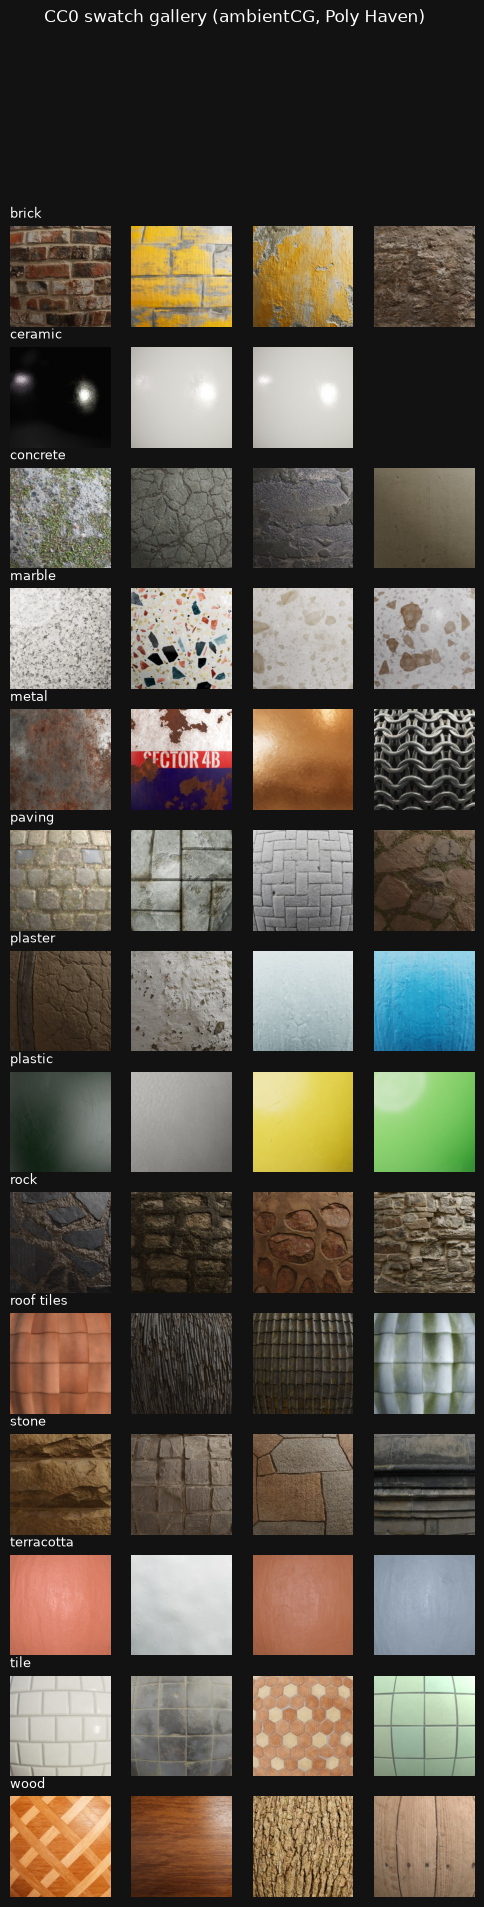

In [5]:
# A look at the gallery: 4 swatches per material
show = swatches.groupby("material").head(4)
mats = sorted(show["material"].unique())
fig, axes = plt.subplots(len(mats), 4, figsize=(6, 1.55 * len(mats)), facecolor="#121212")
for r, mat in enumerate(mats):
    idx = show.index[show["material"] == mat]
    for c in range(4):
        ax = axes[r, c]; ax.axis("off")
        if c < len(idx):
            ax.imshow(Image.open(MODEL_DIR / f"swatch_thumbs/{idx[c]:05d}.jpg"))
    axes[r, 0].set_title(mat, color="white", fontsize=9, loc="left")
plt.suptitle("CC0 swatch gallery (ambientCG, Poly Haven)", color="white")
plt.savefig(FIG_DIR / "19_cc0_swatches.png", dpi=130, bbox_inches="tight", facecolor="#121212")
plt.show()

# 4. Sanity check: do MINC photos find swatches of the right material?

There is no exact match between MINC's 13 classes and the swatch materials (MINC has carpet, glass, mirror, wallpaper; the swatches have concrete, plaster, paving…). For the classes that do match, we check how often the **nearest swatch** has a matching material, for the 3,250 MINC test photos.

In [6]:
# Encode the MINC test photos of the matching classes with the same ONNX model (about 1-2 minutes)
import polars as pl
ALL = ["brick", "carpet", "ceramic", "fabric", "foliage", "food", "glass", "hair", "leather", "metal", "mirror",
       "other", "painted", "paper", "plastic", "polishedstone", "skin", "sky", "stone", "tile", "wallpaper", "water", "wood"]
MATCH = {"brick": {"brick"}, "wood": {"wood"}, "metal": {"metal"}, "stone": {"stone", "rock", "paving"},
         "polishedstone": {"marble", "stone"}, "tile": {"tile", "ceramic"}, "ceramic": {"ceramic", "tile"},
         "plastic": {"plastic"}, "painted": {"plaster", "concrete"}}
files = sorted((DATA_DIR / "minc-2500" / "data").glob("test-*.parquet"))
df = (pl.scan_parquet(files).select(pl.col("image").struct.field("bytes").alias("b"), pl.col("label"))
      .filter(pl.col("label").is_in([ALL.index(k) for k in MATCH])).collect())
start = time.time()
Z_test = np.concatenate([session.run(None, {"image": np.concatenate(
    [preprocess(Image.open(io.BytesIO(b)).convert("RGB")) for b in df["b"][i:i + 32]])})[0]
    for i in range(0, len(df), 32)])
print(f"{len(Z_test):,} test photos encoded in {time.time() - start:.0f} s")

sw_mat = swatches["material"].to_numpy()
nearest = np.argsort(((Z_test[:, None, :] - Z_swatch[None]) ** 2).sum(-1), axis=1)[:, :5]
labels = [ALL[v] for v in df["label"]]
hit1 = [sw_mat[n[0]] in MATCH[l] for n, l in zip(nearest, labels)]
hit5 = [len(set(sw_mat[n]) & MATCH[l]) > 0 for n, l in zip(nearest, labels)]
check = (pd.DataFrame({"MINC class": labels, "nearest swatch matches": hit1, "any of 5 swatches matches": hit5})
         .groupby("MINC class").mean())
check.loc["all"] = [np.mean(hit1), np.mean(hit5)]
counts = Counter(sw_mat)
check["random (nearest)"] = [sum(counts[m] for m in MATCH[c]) / len(sw_mat) if c in MATCH else np.nan
                             for c in check.index[:-1]] + [np.nan]
check.round(3)

2,250 test photos encoded in 95 s


,nearest swatch matches,any of 5 swatches matches,random (nearest)
MINC class,,,
brick,0.632,0.844,0.121
ceramic,0.160,0.464,0.108
metal,0.400,0.736,0.138
painted,0.268,0.596,0.140
plastic,0.092,0.296,0.023
polishedstone,0.312,0.544,0.050
stone,0.572,0.832,0.155
tile,0.412,0.680,0.108
wood,0.748,0.840,0.243


# 5. Write the swatch files (next to the photo gallery, for Hugging Face and the server)

In [7]:
def colour_name(rgb):
    r, g, b = rgb / 255
    mx, mn = max(r, g, b), min(r, g, b)
    if mx < 0.22:
        return "black"
    if mx - mn < 0.08:
        return "white" if mx > 0.75 else "grey"
    hue = (np.degrees(np.arctan2(np.sqrt(3) * (g - b), 2 * r - g - b)) + 360) % 360
    if hue < 18 or hue >= 330:
        return "red"
    if hue < 45:
        return "brown" if mx < 0.6 else "orange"
    if hue < 70:
        return "beige" if mx - mn < 0.25 else "yellow"
    if hue < 170:
        return "green"
    if hue < 260:
        return "blue"
    return "purple"


meta = []
for pos, row in swatches.iterrows():
    meta.append({"id": int(pos), "key": row["key"], "name": row["name"], "material": row["material"],
                 "category": row["category"], "source": row["source"], "link": row["link"],
                 "tags": row["tags"][:8], "colour": colour_name(colours[pos]),
                 "thumb": f"swatch_thumbs/{pos:05d}.jpg", "sphere": f"swatch_spheres/{pos:05d}.jpg"})
np.save(MODEL_DIR / "swatch_latents.npy", Z_swatch)
(MODEL_DIR / "swatch_meta.json").write_text(json.dumps(meta))
print(f"{len(meta):,} swatches written | colours:", Counter(m["colour"] for m in meta).most_common())

1,280 swatches written | colours: [('grey', 433), ('brown', 315), ('orange', 214), ('white', 62), ('red', 60), ('black', 55), ('blue', 47), ('beige', 46), ('green', 28), ('yellow', 20)]


# 6. What we conclude

**✍️ Write this yourselves.**
- How many clean swatches per material, and which materials are missing (glass, mirror, carpet, wallpaper are not in MatSynth's building categories)?
- How often does a MINC photo find a swatch of a matching material (section 4)? Compare with random.
- Swatches are renders of scanned or procedural materials under studio light; photos have real light and context. What does that mean for the matches?
- Licence: all swatches are CC0. Credit ambientCG and Poly Haven in the app anyway.